# Lab01 - sprint 1
Узенбаев Арслан, Полыгина Евгения, Козельцева Полина, Серяга Евгений
## Источники
Открытая база продуктов питания Open Food Facts (https://world.openfoodfacts.org/data). В базе собраны сведения с этикеток продуктов, которые вносят пользователи из разных стран. Мы взяли полную выгрузку от 22.10.2026 и оставили из нее все продукты категории «йогурты» (`en:yogurts`), 37 453 записи. В файле `data/yogurts_off_raw.csv.gz` сохранены только нужные столбцы: штрихкод, название, бренд, страны, категории и пищевая ценность на 100 г.
Объект исследования: один йогурт (товарная позиция). Случайный эксперимент: из всех йогуртов, представленных на рынке и попавших в базу, наугад выбирается один, и с его этикетки считываются значения пищевой ценности. Все величины даны в граммах на 100 г продукта.

Генеральной совокупностью мы считаем все молочные йогурты базы с полностью заполненной пищевой ценностью. Перед анализом данные надо почистить:

- удаляем повторяющиеся штрихкоды;
- оставляем записи, где указаны белки, жиры, углеводы, сахара и энергетическая ценность;
- исключаем растительные йогурты (соевые, кокосовые и т.п.), так как это другой продукт с другим составом;
- удаляем физически невозможные значения: белок больше 25 г (если белка больше, то считаем за спортивное питание, а не за обычный йогурт), жиры больше 30 г, сахаров больше, чем углеводов, сумма белков, жиров и углеводов больше 100 г(защита от опечаток, т.к данные заполняют обычные пользователи);
- удаляем записи, где энергетическая ценность расходится с рассчитанной по составу (формула $4Б + 9Ж + 4У$, подробнее в разделе про белок) больше чем на 15% (формула из энергетической ценности 1 г каждого нутриента). Такое расхождение почти всегда означает ошибку при вводе этикетки. 

Для анализа выбраны три величины: содержание белка, сахаров и жиров. Основное внимание уделено белку.

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display
import lab_utils as lu
lu.set_style()
pd.options.display.float_format = '{:.4g}'.format
raw = pd.read_csv('data/yogurts_off_raw.csv', dtype = {"code": str}) #загружаем датасет
yog, steps = lu.clean_yogurts(raw) #отчищаем его по параметрам, которые описаны выше
display(steps)
print('страны с наибольшим числом йогуртов:')
print(yog['countries_tags'].fillna('').str.split(',').explode().value_counts().head(6)) #берем список стран, разбиваем на список и считаем количество, выводим 6 с самым большим количеством

,шаг,осталось записей
0,исходная выгрузка,37453
1,без повторов штрихкода,37452
2,"заполнены белки, жиры, углеводы, сахара, энергия",33565
3,без растительных йогуртов,33155
4,физически возможные значения,33008
5,энергия согласуется с составом (±15%),32151


страны с наибольшим числом йогуртов:
countries_tags
en:france           8508
en:united-states    5955
en:germany          3006
en:italy            2788
en:spain            2567
en:switzerland      1799
Name: count, dtype: int64


После очистки осталось $N = 32\,151$ йогурт. Больше всего продуктов из Франции и США. В очищенной базе оказалось 70 продуктов с меткой продажи в России. Причину исключения остальных российских записей нужно отдельно проверять по исходным данным; по одному итоговому числу её установить невозможно. Метки стран обозначают рынки продажи, но не обязательно страну производства.

Уточнение к правилам очистки: код допускает сахара до углеводов + 0.5 г и расхождение энергии до 15% от расчётного значения + 5 ккал. Также отбрасываются отрицательные значения нутриентов и углеводы выше 60 г. Пределы белка 25 г и жиров 30 г — принятые фильтры анализа, а не универсальные физические границы.


In [2]:
lu.describe_table({c: yog[c] for c in ['proteins_100g', 'sugars_100g', 'fat_100g']})

,proteins_100g,sugars_100g,fat_100g
n,3.215e+04,3.215e+04,3.215e+04
E,4.521,9.31,2.944
D,5.087,19.7,6.888
sigma,2.255,4.438,2.624
"CV, %",49.89,47.67,89.14
min,0,0,0
Q1,3.2,5,1
медиана,3.7,10,2.734
Q3,5,12.67,3.7
max,25,59.1,29.6


Все три величины имеют большой относительный разброс (коэффициент вариации от 48% до 89%), то есть йогурты сильно различаются по составу. У белка и жиров заметна правая асимметрия. У сахаров асимметрия почти нулевая, но близкая к нулю. Асимметрия сама по себе не означает нормальность распределения.

## Random Variable 01 (белок)
### Описание

Содержание белка в йогурте определяется в первую очередь молоком: в коровьем молоке около 3.2–3.4 г белка на 100 г (казеин и сывороточные белки), и при сквашивании это количество почти не меняется. Дальше все зависит от технологии и рецептуры. Если после сквашивания отделить часть сыворотки (греческий йогурт, скир), белок концентрируется и может доходить до 8–10 г. Если добавить сухое молоко или молочный белок, содержание тоже растет. Если же добавить фруктовый наполнитель или сироп, белок, наоборот, разбавляется. Кроме того, значение на этикетке округляется, и производитель может указывать его с допуском.

Поэтому для случайно выбранного йогурта содержание белка заранее неизвестно: оно зависит от рецептуры, которой в данных нет. Проверим, насколько точно его можно восстановить по остальным выбранным показателям.

Для сравнения сначала рассмотрим величину, которая как раз вычисляется по формуле. Энергетическая ценность продукта рассчитывается по составу с помощью коэффициентов Этуотера: 1 г белка или углеводов дает около 4 ккал, 1 г жира около 9 ккал:

$$E_{ккал} \approx 4Б + 9Ж + 4У$$

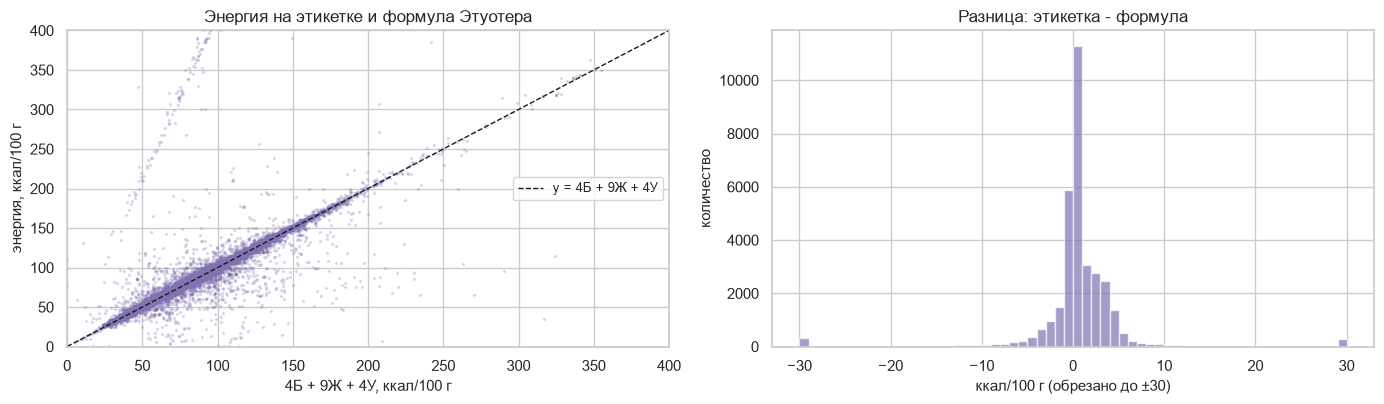

записей                     3.347e+04
медиана |разницы|, ккал           0.9
доля |разницы| <= 5 ккал        0.908
доля |разницы| <= 10 ккал       0.956
dtype: float64

In [ ]:
pd.Series(lu.atwater_check(raw)).round(3)#графики: разница между теоритическими значениями каллорийности и указанной; распределение этой разницы

У 91% йогуртов (до очистки по этому признаку) значение на этикетке отличается от формулы не больше чем на 5 ккал, медианное расхождение 0.9 ккал. Это приближённая расчётная зависимость: энергия тесно связана с составом. Остаточное расхождение может быть связано с округлением (На самом деле на 1 г белка и углевода приходится 4,1 ккал, а на 1 г жира 9,4 ккал ), особенностями расчёта энергетической ценности и ошибками в данных. В этой проверке энергию исключаем из признаков: она непосредственно связана с белком расчётной формулой и сделала бы восстановление состава частично круговым (т.к. значения, вычисленные по формуле очень близки к указанным и разницв является систематической, вычисление нутриентов из этой формулы не имеет смысла в нашей работе).

Теперь попробуем предсказать белок по жирам, углеводам и сахарам. Используем случайный лес (модель, которая может уловить и нелинейные зависимости) с кросс-валидацией на 5 частях, чтобы оценка качества была честной. Высокий $R^2$ означал бы хорошее качество предсказания, но низкий $R^2$ сам по себе не доказывает отсутствия детерминированной зависимости: модель может не восстановить её. Дополнительно для каждого йогурта найдем ближайшего «двойника» по жирам, углеводам и сахарам и сравним белок у них.

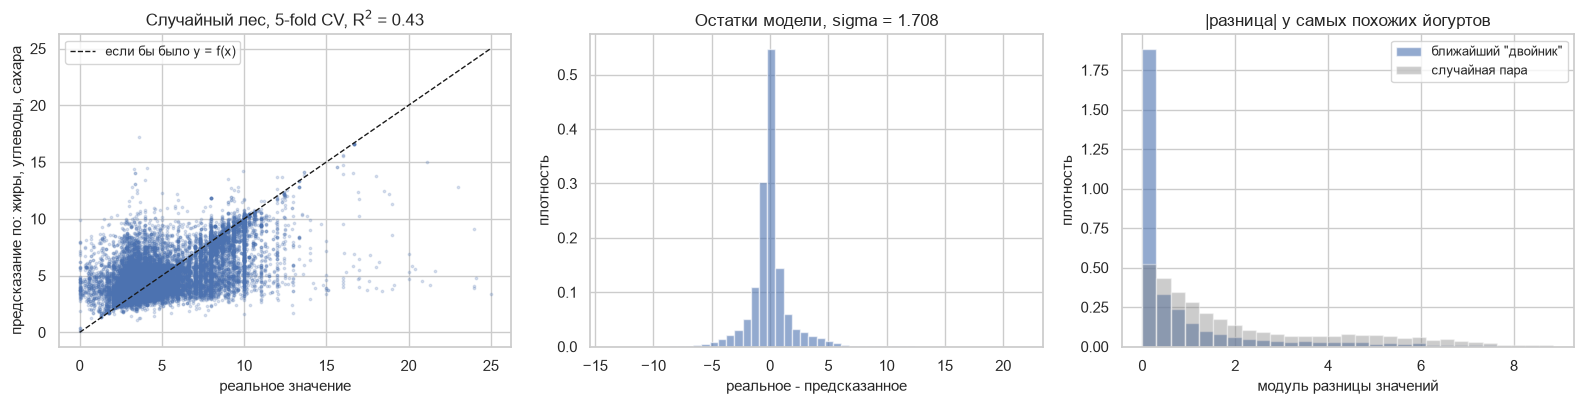

R2 (CV)                             0.427
sigma остатков                      1.708
sigma величины                      2.255
медиана |разн.| у двойников           0.2
медиана |разн.| у случайных пар      1.32
доля двойников с другим значением   0.602
dtype: float64

In [2]:
features_p = ['fat_100g', 'carbohydrates_100g', 'sugars_100g']
rand_p = lu.randomness_check(yog, 'proteins_100g', features_p)
pd.Series(rand_p).round(3)

$R^2 = 0.43$: по остальным составляющим объясняется меньше половины разброса белка, остаточное стандартное отклонение 1.7 г при общем 2.3 г. Медианная разница белка у двойников 0.2 г против 1.3 г у случайной пары, то есть выбранная модель обнаруживает связь с составом, но не восстанавливает белок полностью.

Еще нагляднее посмотреть на группы йогуртов с полностью совпадающими жирами, углеводами и сахарами:

In [ ]:
twins = lu.twins_exact(yog, 'proteins_100g', features_p)
print('групп из 5 и более йогуртов с одинаковыми жирами, углеводами и сахарами:', len(twins))
print('из них с разным белком:', (twins['размах'] > 0).mean().round(3))
twins.head(8).round(2)

В 75% таких групп белок различается. Например, у 94 йогуртов одинаково указаны 10 г жиров, 4 г углеводов и 4 г сахаров (это в основном жирные греческие йогурты), а белок у них от 2.8 до 9 г. Следовательно, по совпадающим значениям этих трёх показателей на этикетке нельзя однозначно восстановить указанный белок. Случайная величина X здесь задаётся экспериментом: мы равновероятно выбираем продукт из очищенной базы и считываем содержание белка.

Также проверим, случаен ли порядок записей в файле: от этого зависит, как формировать выборку.

In [ ]:
order_p = lu.order_check(yog['proteins_100g'], 'proteins_100g')
print(f"доля продуктов из США: в первых 1000 строках {yog['usa'].iloc[:1000].mean():.3f}, во всей совокупности {yog['usa'].mean():.3f}")
pd.Series(order_p).round(4)

Критерий серий отвергает гипотезу о случайном порядке ($p \approx 10^{-203}$), автокорреляция соседних записей 0.22, а после перемешивания почти 0. Записи сгруппированы: в первых 1000 строках 92.5% американских продуктов при 18.5% во всей совокупности. Поэтому выборку нельзя брать как первые $n$ строк файла, ее нужно формировать случайно.

<a id="rv01-eda"></a>
### Анализ данных и подбор распределения

In [ ]:
x = yog['proteins_100g']
lu.eda_plots(x, 'proteins_100g')
out, low, high = lu.outliers_iqr(x)
print(f'выбросов по правилу 1.5 IQR: {len(out)} ({len(out) / len(x) * 100:.1f}%), границы [{low:.2f}, {high:.2f}]')
print('разных значений:', x.nunique())
print('самые частые значения:', x.round(2).value_counts().head(6).to_dict())

Распределение явно несимметричное: среднее 4.52 г больше медианы 3.70 г, асимметрия 1.73. Основная масса йогуртов лежит в диапазоне 3–4 г, но справа есть длинный хвост и отдельный подъем около 8–10 г. По правилу 1.5 IQR выбросами оказываются 13.8% значений, почти все они справа. Однако правило IQR само по себе не устанавливает ошибочность записи. Высокий белок может соответствовать реальному составу продукта, поэтому только по этому правилу значения не удаляем.

Видно также, что значения часто повторяются (3.5, 3.0, 3.3 и т.д.): производители округляют данные на этикетке до десятых. Предположим, что второй подъем дают греческие и высокобелковые йогурты, и проверим это.

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.arange(0, 16, 0.25)
ax.hist(x[~yog['greek']], bins=bins, density=True, alpha=0.5, color=lu.COLORS['proteins_100g'], label=f"остальные (n = {(~yog['greek']).sum()})")
ax.hist(x[yog['greek']], bins=bins, density=True, alpha=0.5, color='#C44E52', label=f"греческие (n = {yog['greek'].sum()})")
ax.set_title('Белок в греческих и остальных йогуртах')
ax.set_xlabel(lu.LABELS['proteins_100g'])
ax.set_ylabel('плотность')
ax.legend()
plt.tight_layout()
plt.show()
print('медиана белка: греческие', x[yog['greek']].median(), '| остальные', x[~yog['greek']].median())
print('доля йогуртов с белком от 6 г:', round((x >= 6).mean(), 3))

Предположение подтверждается: у греческих йогуртов медиана 6.0 г против 3.6 г у остальных, что согласуется с их вкладом в правый подъём. Около 19% всех йогуртов содержат 6 г белка и больше. Результаты мотивируют приближение распределения смесью двух компонент. Они не доказывают, что каждый продукт можно однозначно отнести к одному из двух технологических типов. Это нужно учитывать при выборе модели распределения.

Сравним несколько моделей. Параметры подбираются методом максимального правдоподобия, модели сравниваются по информационным критериям $AIC = 2k - 2\ln L$ и $BIC = k\ln n - 2\ln L$, где $k$ это число параметров, $L$ это значение функции правдоподобия. Чем меньше критерий, тем лучше модель; BIC сильнее штрафует за лишние параметры. Для логарифма нужны положительные значения, поэтому 58 йогуртов с нулевым белком исключены из подбора. Подобранная модель описывает условное распределение при X > 0; нулевые значения она не моделирует.

In [ ]:
xp = x[x > 0]
mix_p = lu.fit_mixture(xp, k=2, log=True)
display(lu.fit_table(xp, mix_p))
display(lu.mixture_table(mix_p))
lu.plot_fits(xp, 'proteins_100g', mix_p, xmax=15)
e_mix = sum(w * np.exp(m + s ** 2 / 2) for w, m, s in zip(mix_p['w'], mix_p['mu'], mix_p['sd']))
print(f'среднее по модели смеси: {e_mix:.3f}, среднее в данных: {xp.mean():.3f}')
print(f"удалено нулевых значений для логарифма: {(x == 0).sum()}")

Из моделей с одной компонентой лучше всего подходит логнормальная, но она не может описать второй подъем. Смесь двух логнормальных распределений дает наименьшие AIC и BIC и хорошо повторяет эмпирическую функцию распределения. Первая компонента (85% йогуртов) имеет медиану 3.57 г, что соответствует обычному молоку, вторая (15%) имеет медиану 8.75 г, это согласуется с возможным вкладом концентрированных или обогащённых продуктов. Компоненты статистической смеси не являются установленной классификацией продуктов. Среднее по модели (4.55 г) почти совпадает со средним по данным (4.53 г).

<a id="rv01-math"></a>
#### Математическое описание распределения

Логнормальное распределение. Случайная величина $X > 0$ имеет логнормальное распределение, если ее логарифм распределен нормально: $\ln X \sim N(\mu, \sigma^2)$. Плотность:

$$f(x) = \frac{1}{x\sigma\sqrt{2\pi}} \exp\left(-\frac{(\ln x - \mu)^2}{2\sigma^2}\right), \quad x > 0$$

Основные характеристики: медиана $e^{\mu}$, математическое ожидание $EX = e^{\mu + \sigma^2/2}$. Так как $EX > e^{\mu}$, распределение всегда скошено вправо. Оценки параметров по методу максимального правдоподобия: $\mu$ равно среднему значению $\ln x_i$, $\sigma = \sqrt{\frac{1}{n}\sum_i(\ln x_i-\hat\mu)^2}$ (делитель n, а не n − 1).

Почему для белка естественно ожидать логнормальное распределение?Содержание белка получается как произведение нескольких факторов: исходный белок молока, коэффициент концентрирования (сколько сыворотки удалили), доля молочной основы в продукте (сколько добавили наполнителя). Логарифм произведения равен сумме логарифмов. Это заставляет рассмотреть логнормальной модели, но не доказывает её: число факторов невелико, их независимость и условия центральной предельной теоремы не установлены. Пригодность модели нужно оценивать по данным.

Смесь распределений. Если совокупность состоит из нескольких групп, то плотность всей совокупности равна взвешенной сумме плотностей групп:

$$f(x) = w_1 f_1(x) + w_2 f_2(x), \quad w_1 + w_2 = 1$$

Такую модель удобно понимать как двухшаговый эксперимент: сначала с вероятностью $w_1$ выбирается первая компонента модели, а с вероятностью $w_2$ вторая, затем содержание белка берется из распределения соответствующей группы. Математическое ожидание смеси $EX = w_1 EX_1 + w_2 EX_2$. В нашей модели $f_1$ и $f_2$ логнормальные плотности. Параметры смеси нельзя выписать явной формулой, поэтому они находятся численно, EM-алгоритмом: на каждом шаге для каждого йогурта оценивается вероятность принадлежности к каждой группе, затем по этим вероятностям пересчитываются веса и параметры групп, и так до сходимости.

<a id="rv01-norm"></a>
#### Нормализация

Min-max нормализация $x' = \frac{x - \min}{\max - \min}$ переводит значения в отрезок $[0, 1]$ и не меняет форму распределения. Ее недостаток в чувствительности к крайним значениям: один йогурт с 25 г белка сжимает все остальные значения к началу отрезка.

Стандартизация $z = \frac{x - \mu}{\sigma}$ переводит величину в единицы стандартного отклонения: $z = 1.5$ означает, что значение на полторы сигмы больше среднего. После нее $E z = 0$ и $D z = 1$. Если исходная величина распределена нормально, то $z$ имеет стандартное нормальное распределение $N(0, 1)$: линейное преобразование нормальной величины тоже дает нормальную величину. Это удобно, потому что разные величины оказываются в одной шкале, их можно сравнивать между собой, а вероятности можно находить по одной таблице для $N(0, 1)$.

Проверим логарифмирование положительных значений белка с последующей стандартизацией. Для смеси логнормальных распределений это преобразование в общем случае не даёт нормального распределения. В коде используется выборочное стандартное отклонение с делителем n − 1: выборочная дисперсия z равна 1, а эмпирическая дисперсия с делителем n равна (n − 1)/n.

In [ ]:
z_p = lu.normalize_plots(xp, 'proteins_100g', log=True)
print(f'E(z) = {z_p.mean():.2e}, sigma(z) = {z_p.std():.4f}')
for k, ref in [(1, 0.683), (2, 0.954), (3, 0.997)]:
    print(f'доля |z| < {k}: {np.mean(np.abs(z_p) < k):.3f} (у N(0, 1) {ref})')

После логарифмирования распределение стало заметно симметричнее, но до стандартного нормального не дотягивает: в интервал $|z| < 1$ попадает 74% значений вместо 68%, а за пределы $3\sigma$ выходит 0.9% вместо 0.3%. Острая вершина и тяжелые хвосты объясняются тем, что это смесь двух групп. Стандартизация, как и любое линейное преобразование, форму распределения не меняет.

<a id="rv01-est"></a>
### Независимость и оценки

Белок и жиры относятся к одной группе показателей (макронутриенты молочной основы). Проверим, зависимы ли они.

$H_0$: содержание белка и жиров независимы. Используем коэффициенты корреляции Пирсона (линейная связь) и Спирмена (монотонная связь), а также критерий хи-квадрат по таблице сопряженности групп. Силу связи по хи-квадрату оценим коэффициентом V Крамера (0 означает отсутствие связи, 1 полную связь). Уровень значимости здесь и далее $\alpha = 0.05$.

In [ ]:
p, f = yog['proteins_100g'], yog['fat_100g']
print(f'Пирсон: r = {stats.pearsonr(p, f).statistic:.3f}, p = {stats.pearsonr(p, f).pvalue:.3g}')
print(f'Спирмен: rho = {stats.spearmanr(p, f).statistic:.3f}, p = {stats.spearmanr(p, f).pvalue:.3g}')
fat_group = pd.cut(f, [-0.01, 0.5, 2, 4, 30], labels=['до 0.5', '0.5-2', '2-4', 'больше 4'])
prot_group = pd.cut(p, [-0.01, 3, 4, 6, 25], labels=['до 3', '3-4', '4-6', 'больше 6'])
table = pd.crosstab(fat_group, prot_group)
chi2, p_chi, dof, _ = stats.chi2_contingency(table)
print(f'хи-квадрат: chi2 = {chi2:.0f}, df = {dof}, p = {p_chi:.3g}, V Крамера = {np.sqrt(chi2 / (table.values.sum() * 3)):.3f}')
sample = yog.sample(1000, random_state=5)
print(f"на случайной выборке n = 1000: rho = {stats.spearmanr(sample['proteins_100g'], sample['fat_100g']).statistic:.3f}, p = {stats.spearmanr(sample['proteins_100g'], sample['fat_100g']).pvalue:.3g}")
display(pd.crosstab(fat_group, prot_group, normalize='index').round(3))
fig, ax = plt.subplots(figsize=(9, 4))
for g in fat_group.cat.categories:
    ax.hist(p[fat_group == g], bins=np.arange(0, 16, 0.5), density=True, histtype='step', lw=1.5, label=f'жиры {g} г')
ax.set_title('Распределение белка в группах по жирности')
ax.set_xlabel(lu.LABELS['proteins_100g'])
ax.set_ylabel('плотность')
ax.legend()
plt.tight_layout()
plt.show()

Критерий хи-квадрат отвергает независимость сгруппированных показателей. Пирсон и Спирмен дополнительно обнаруживают статистически значимую корреляцию; сами эти критерии проверяют отсутствие соответствующей корреляции, а не независимость в общем случае. Корреляция отрицательная, но слабая ($\rho = -0.20$), а по хи-квадрату связь умеренная (V = 0.28). Таблица показывает различия распределения белка между группами жирности: среди обезжиренных йогуртов почти половина содержит больше 6 г белка, а среди йогуртов с жирностью 2–4 г таких только 7%. Возможное объяснение связано с ассортиментом: высокобелковые продукты (скир, греческие йогурты для спортивного питания) чаще всего делают обезжиренными. На случайной выборке из 1000 йогуртов вывод тот же ($\rho = -0.13$, $p = 2 \cdot 10^{-5}$).

Состоятельность оценок. Оценка $\hat\theta_n$ параметра $\theta$ называется состоятельной, если при росте объема выборки она сходится к истинному значению по вероятности:

$$P(|\hat\theta_n - \theta| > \varepsilon) \to 0, \quad n \to \infty \quad \text{для любого } \varepsilon > 0$$

Для выборочного среднего это следует из закона больших чисел при независимых одинаково распределённых наблюдениях с конечным ожиданием. Для дисперсии достаточно конечного второго момента. Для медианы нужны условия на распределение в окрестности единственной медианы. В эксперименте выборки строятся с возвращением из конечной базы.

Проверим это эмпирически. Генеральную совокупность считаем известной, из нее извлекаем выборки с возвращением объемом $n$ по 500 раз для каждого $n$ и считаем долю случаев, когда оценка отклонилась от значения в генеральной совокупности больше чем на $\varepsilon = 0.1\sigma$.

In [ ]:
cons_p = lu.consistency_plots(x, 'proteins_100g')
cons_p.round(5)

Для всех трех оценок (среднее, стандартное отклонение, медиана) доля больших ошибок падает с 66–85% при $n = 5$ практически до нуля при $n \ge 2000$, траектории выборочного среднего сходятся к 4.52. Результаты численного эксперимента согласуются с теоретической состоятельностью оценок; конечное число повторов само по себе не доказывает сходимость при n → ∞. Среднеквадратичная ошибка среднего совпадает с теоретической $\sigma^2/n$, то есть корень из среднеквадратичной ошибки убывает как $1/\sqrt{n}$. Медиана здесь сходится быстрее среднего, потому что она находится в самом плотном месте распределения и не чувствительна к правому хвосту.

<a id="rv01-samp"></a>
### Выборка

Выборка с возвращением: каждый йогурт может попасть в выборку несколько раз, наблюдения независимы и одинаково распределены, поэтому дисперсия выборочного среднего равна $D\bar X = \frac{\sigma^2}{n}$.

Выборка без возвращения: каждый йогурт попадает не больше одного раза. Наблюдения становятся зависимыми, и дисперсия среднего уменьшается:

$$D\bar X = \frac{\sigma^2}{n} \cdot \frac{N - n}{N - 1}$$

Множитель $\frac{N-n}{N-1}$ называется поправкой на конечность совокупности. При $n \ll N$ он близок к 1, а при $n = N$ равен 0: выборка совпадает с генеральной совокупностью.

Возьмем выборку объемом $n = 1000$ (около 3% совокупности) двумя способами и сравним с генеральной. Для сравнения добавим первые 1000 строк файла.

In [ ]:
table_p, s_with_p, s_without_p = lu.sample_compare(x)
table_p

Обе случайные выборки хорошо описывают генеральную совокупность: среднее 4.54 и 4.60 при 4.52, медиана и квартили отличаются не больше чем на 0.1 г, в исходном расчёте получены KS p-value 0.80 и 0.74. Эти значения приведены только как диагностические: выборка взята из сравниваемой базы и не независима от неё, а округление создаёт повторяющиеся значения. Обычная интерпретация двухвыборочного KS-теста здесь не обоснована. Хуже всего оцениваются асимметрия и особенно эксцесс (2.3 и 6.2 при 4.1), так как они определяются редкими значениями в хвосте. В выборку с возвращением попало 989 разных йогуртов, остальное повторы.

Первые 1000 строк файла дают совсем другую картину: среднее 5.51, медиана 4.58, наблюдается заметное отличие эмпирических распределений. KS p-value здесь также не рассматриваем как корректный уровень значимости. Это следствие неслучайного порядка записей.

Проверим формулы для дисперсии среднего. Для каждого $n$ извлечем по 1000 выборок и посчитаем дисперсию полученных средних.

In [ ]:
lu.fpc_experiment(x)

Экспериментальные значения совпадают с теоретическими. При малых $n$ способы почти не отличаются, а при $n = 20\,000$ (62% совокупности) дисперсия среднего без возвращения меньше в 2.9 раза, при $n = 30\,000$ в 16 раз. Вывод: если выборка составляет заметную долю генеральной совокупности, выборка без возвращения дает более точную оценку; при $n \ll N$ разницы между способами практически нет.

<a id="rv01-hyp"></a>
### Гипотеза

H1. $H_0$: положительные значения содержания белка описываются одним логнормальным распределением. Проверка по выборке без возвращения $n = 1000$ критерием Шапиро-Уилка для $\ln X$, затем сравнение одно- и двухкомпонентной модели по BIC.

In [ ]:
for name, s in [('выборка без возвращения, n = 1000', s_without_p[s_without_p > 0]), ('генеральная совокупность', xp)]:
    print(name)
    print(f'   белок, Шапиро-Уилк: p = {stats.shapiro(s).pvalue:.3g}')
    print(f'   ln(белок), Шапиро-Уилк: p = {stats.shapiro(np.log(s)).pvalue:.3g}')
print()
print('сравнение моделей на выборке n = 1000 по BIC:')
sp = s_without_p[s_without_p > 0]
one = lu.fit_mixture(sp, k=1, log=True)
two = lu.fit_mixture(sp, k=2, log=True)
for m in [one, two]:
    k = 3 * m['k'] - 1
    print(f"   {m['name']}: BIC = {k * np.log(len(sp)) - 2 * m['logL']:.1f}")
print(f"веса смеси по выборке: {two['w'].round(3)}, медианы компонент: {np.exp(two['mu']).round(2)}")

Гипотеза отвергается: $p \approx 3 \cdot 10^{-22}$ уже на выборке, расчёт по полной базе приводится дополнительно. Двухкомпонентная смесь по выборке дает меньший BIC, а ее параметры (веса 0.82 и 0.18, медианы 3.55 и 8.6 г) близки к параметрам по всей совокупности. В этой конкретной выборке параметры близки к оценкам по базе; это не гарантирует такого же результата для любой выборки объёма 1000. Для n > 5000 точность p-value Шапиро—Уилка ограничена. Кроме того, округление и повторяющиеся значения отклоняются от предпосылки непрерывной модели. BIC служит сравнением моделей, а не отдельным тестом с p-value.

H2. $H_0$: распределение белка в российских йогуртах такое же, как в остальных. Российских йогуртов всего 70, распределение далеко от нормального, поэтому основным выбран непараметрический критерий Манна-Уитни. Критерий Уэлча приведён отдельно: он проверяет равенство средних, а не совпадение распределений. Метка russia обозначает продажу в России. Статистические выводы относятся к записям базы и не переносятся автоматически на весь рынок.

In [ ]:
ru = yog.loc[yog['russia'], 'proteins_100g']
other = yog.loc[~yog['russia'], 'proteins_100g']
u = stats.mannwhitneyu(ru, other, alternative='two-sided')
t = stats.ttest_ind(ru, other, equal_var=False)
print(f'Россия: n = {len(ru)}, медиана {ru.median():.2f}, среднее {ru.mean():.2f}')
print(f'остальные: n = {len(other)}, медиана {other.median():.2f}, среднее {other.mean():.2f}')
print(f'доля греческих: Россия {yog.loc[yog["russia"], "greek"].mean():.3f}, остальные {yog.loc[~yog["russia"], "greek"].mean():.3f}')
print(f'Манн-Уитни: U = {u.statistic:.0f}, p = {u.pvalue:.3g}')
print(f'Уэлч: t = {t.statistic:.2f}, p = {t.pvalue:.3g}')
reg = yog[~yog['greek']]
u2 = stats.mannwhitneyu(reg.loc[reg['russia'], 'proteins_100g'], reg.loc[~reg['russia'], 'proteins_100g'])
print(f"только не греческие: медиана Россия {reg.loc[reg['russia'], 'proteins_100g'].median():.2f}, остальные {reg.loc[~reg['russia'], 'proteins_100g'].median():.2f}, Манн-Уитни p = {u2.pvalue:.3g}")
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.arange(0, 12, 0.4)
ax.hist(other, bins=bins, density=True, alpha=0.5, color=lu.COLORS['proteins_100g'], label='остальные страны')
ax.hist(ru, bins=bins, density=True, alpha=0.6, color='#C44E52', label='Россия')
ax.set_title('Белок в российских и остальных йогуртах')
ax.set_xlabel(lu.LABELS['proteins_100g'])
ax.set_ylabel('плотность')
ax.legend()
plt.tight_layout()
plt.show()

По всем йогуртам гипотеза не отвергается: $p = 0.073 > 0.05$, хотя медиана в России ниже (3.3 г против 3.7 г). Наблюдаемые доли греческих йогуртов близки (около 12%). Неотвержение H0 не доказывает совпадение распределений. Если же сравнить только обычные йогурты, без греческих, то различие становится значимым: медиана 3.25 г против 3.60 г, $p = 0.009$. В подгруппе без греческих йогуртов обнаружено различие по критерию Манна—Уитни, а наблюдаемая медиана у российских продуктов ниже. Этот критерий не проверяет равенство средних. Анализ подгруппы является дополнительным, поэтому без отдельного плана проверок результат следует считать исследовательским. Этот вывод предварительный: 70 продуктов могут быть не вполне представительны для российского рынка.

<a id="rv01-res"></a>
### Общий вывод

Содержание белка у равновероятно выбранного продукта — случайная величина. Случайный лес объясняет около 43% его разброса по жирам, углеводам и сахарам; при одинаковых значениях этих показателей указанный белок может различаться. Положительные значения белка приближённо описываются смесью двух логнормальных компонент (85%, медиана 3.6 г; 15%, медиана 8.8 г). Интерпретация компонент как обычных и концентрированных йогуртов — содержательная гипотеза. Наблюдается отрицательная корреляция белка и жиров; причинная связь этим не установлена. Оценки среднего, стандартного отклонения и медианы состоятельны, случайная выборка объемом 1000 хорошо описывает генеральную совокупность.